# R e Python no mesmo notebook: o caged.duckdb do datacaged

Notebook de [alexsandroprado.site/blog/posts/datacaged-python](https://alexsandroprado.site/blog/posts/datacaged-python/), por Alexsandro Prado (UFERSA).

O pacote [datacaged](https://alexsandroprado.site/producao-tecnica/#datacaged), escrito em R, grava os microdados do Cadastro Geral de Empregados e Desempregados (CAGED) em um arquivo DuckDB (`caged.duckdb`). Como o DuckDB possui bibliotecas para diversas linguagens, o mesmo arquivo pode ser consultado em R e em Python. Neste notebook, o *kernel* é o Python, e as células em R são executadas por meio do comando mágico `%%R` do pacote `rpy2`, que também permite a troca de tabelas entre as duas linguagens:

- `%%R -o objeto`: envia um objeto do R para o Python;
- `%%R -i objeto`: envia um objeto do Python para o R.

Os exemplos utilizam as competências de julho a setembro de 2026 do Novo CAGED.

## Requisitos

- **R** (versão 4.4 ou superior, recomendada para as versões atuais do `rpy2`), com os pacotes `datacaged`, `duckdb`, `dplyr`, `tidyr` e `ggplot2`;
- **Python**, com `duckdb`, `pandas`, `polars`, `matplotlib` e `rpy2`.

O notebook funciona no Jupyter, no VS Code e no Google Colab. Recomenda-se que a versão do `duckdb` em Python seja igual ou superior à do pacote `duckdb` do R que criou o banco, tendo em vista que versões mais novas do DuckDB leem arquivos de versões anteriores, mas o contrário nem sempre ocorre. Na primeira execução, retire o comentário da linha `%pip install` abaixo; os pacotes do R que estiverem faltando são instalados automaticamente pela célula seguinte.

In [1]:
# %pip install duckdb pandas polars matplotlib rpy2

%load_ext rpy2.ipython

In [2]:
%%R
pacotes <- c("datacaged", "duckdb", "dplyr", "tidyr", "ggplot2")
faltantes <- setdiff(pacotes, rownames(installed.packages()))

if (length(faltantes) > 0) {
  install.packages(faltantes)
} else {
  cat("Todos os pacotes do R já estão instalados.
")
}
invisible()

Todos os pacotes do R já estão instalados.


## Passo 1 (R): carregar os microdados

O `datacaged` baixa, padroniza e grava os dados em um único comando. Como a operação leva alguns minutos, a célula a seguir só executa o carregamento quando o arquivo `caged.duckdb` ainda não existe na pasta do notebook.

In [3]:
%%R
if (!file.exists("caged.duckdb")) {
  library(datacaged)
  caged_load(years = 2026, months = 7:9, db_path = "caged.duckdb")
} else {
  cat("Banco caged.duckdb encontrado; o carregamento não é necessário.
")
}
invisible()

Banco caged.duckdb encontrado; o carregamento não é necessário.


Com o banco criado, a conexão em R pode ser feita diretamente pelo pacote `duckdb` (a função `caged_connect()` do `datacaged` é equivalente), em modo de leitura, uma vez que o DuckDB admite apenas um processo com permissão de escrita por vez. A seguir, o R calcula o saldo de empregos formais por unidade da federação com `dplyr` e envia o resultado ao Python com `-o saldo_uf`.

In [4]:
%%R -o saldo_uf
suppressPackageStartupMessages(library(dplyr))

con_r <- DBI::dbConnect(duckdb::duckdb(), "caged.duckdb", read_only = TRUE)
print(DBI::dbListTables(con_r))

saldo_uf <- tbl(con_r, "caged_mov") |>
  group_by(uf) |>
  summarise(saldo = sum(saldomovimentacao, na.rm = TRUE)) |>
  filter(uf != 99) |>
  arrange(desc(saldo)) |>
  collect() |>
  as.data.frame()

DBI::dbDisconnect(con_r, shutdown = TRUE)
head(saldo_uf)

[1] "caged_exc" "caged_for" "caged_mov"
  uf saldo
1 35 79738
2 33 31431
3 26 28682
4 29 25937
5 31 23336
6 23 18632


## Passo 2 (Python): consultar o mesmo banco

Em Python, a conexão é aberta com `duckdb.connect()`, também em modo de leitura. A variável `saldomovimentacao` assume o valor 1 para admissões e -1 para desligamentos, de modo que sua soma corresponde ao saldo de empregos formais.

In [5]:
import duckdb

con = duckdb.connect("caged.duckdb", read_only=True)

saldo_mensal = con.sql("""
    SELECT
        competenciamov::INT                                          AS competencia,
        SUM(CASE WHEN saldomovimentacao =  1 THEN 1 ELSE 0 END)::INT AS admissoes,
        SUM(CASE WHEN saldomovimentacao = -1 THEN 1 ELSE 0 END)::INT AS desligamentos,
        SUM(saldomovimentacao)::INT                                  AS saldo
    FROM caged_mov
    GROUP BY 1
    ORDER BY 1
""").df()
saldo_mensal

,competencia,admissoes,desligamentos,saldo
0,202607,2262888,2204320,58568
1,202608,2294563,2128736,165827
2,202609,2214437,2093132,121305


A consulta seguinte calcula o salário de admissão de contadores (código 252210 da Classificação Brasileira de Ocupações, CBO) por sexo, considerando apenas vínculos não intermitentes com salário entre R\$ 500 e R\$ 60.000. No Novo CAGED, a variável `sexo` assume o valor 1 para homens e 3 para mulheres.

In [6]:
contadores = con.sql("""
    SELECT
        CASE sexo WHEN 1 THEN 'Homens' WHEN 3 THEN 'Mulheres' END AS sexo,
        COUNT(*)                     AS admissoes,
        ROUND(MEDIAN(salario))       AS salario_mediano,
        ROUND(AVG(salario))          AS salario_medio
    FROM caged_mov
    WHERE cbo2002ocupacao = 252210
      AND saldomovimentacao = 1
      AND indtrabintermitente = 0
      AND salario BETWEEN 500 AND 60000
    GROUP BY 1
    ORDER BY 1
""").df()
contadores

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,sexo,admissoes,salario_mediano,salario_medio
0,Homens,4173,4680.0,6100.0
1,Mulheres,6344,4500.0,5269.0


## Passo 3: trocar resultados entre as linguagens

O Python recebe a tabela `saldo_uf`, calculada em R no Passo 1, e agrega o saldo por região com `Polars`. O primeiro dígito do código de unidade da federação do Instituto Brasileiro de Geografia e Estatística (IBGE) identifica a região.

shape: (5, 2)
┌──────────────┬────────┐
│ regiao       ┆ saldo  │
│ ---          ┆ ---    │
│ str          ┆ i64    │
╞══════════════╪════════╡
│ Sul          ┆ 20171  │
│ Centro-Oeste ┆ 26536  │
│ Norte        ┆ 36726  │
│ Nordeste     ┆ 127471 │
│ Sudeste      ┆ 134239 │
└──────────────┴────────┘


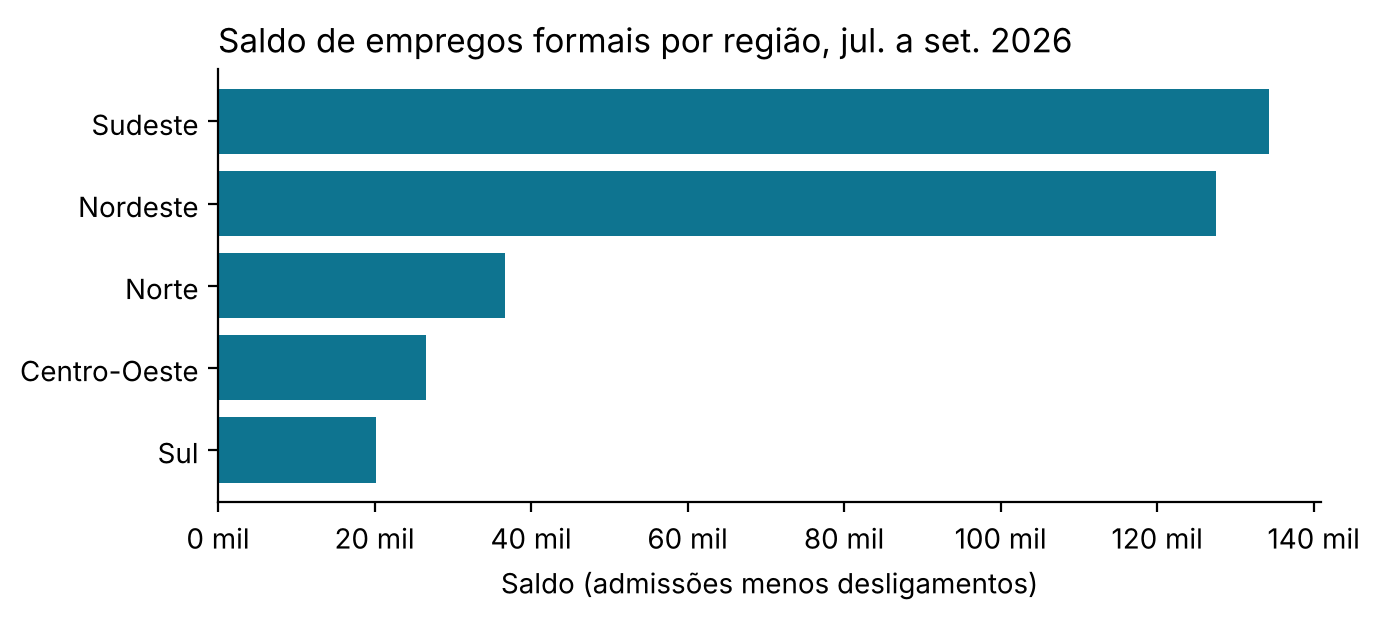

In [7]:
import polars as pl
import matplotlib.pyplot as plt

regioes = {1: "Norte", 2: "Nordeste", 3: "Sudeste", 4: "Sul", 5: "Centro-Oeste"}

saldo_regiao = (
    pl.from_pandas(saldo_uf)
    .with_columns((pl.col("uf") // 10).cast(pl.Int64).replace_strict(regioes).alias("regiao"))
    .group_by("regiao")
    .agg(pl.col("saldo").sum().cast(pl.Int64))
    .sort("saldo")
)
print(saldo_regiao)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(saldo_regiao["regiao"], saldo_regiao["saldo"], color="#0e7490")
ax.xaxis.set_major_formatter(lambda x, p: f"{x / 1000:.0f} mil")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Saldo (admissões menos desligamentos)")
ax.set_title("Saldo de empregos formais por região, jul. a set. 2026", loc="left")
plt.tight_layout()
plt.show()

No sentido inverso, o R recebe a tabela `contadores`, calculada em Python no Passo 2, por meio de `-i contadores`, e produz o gráfico com `ggplot2`.

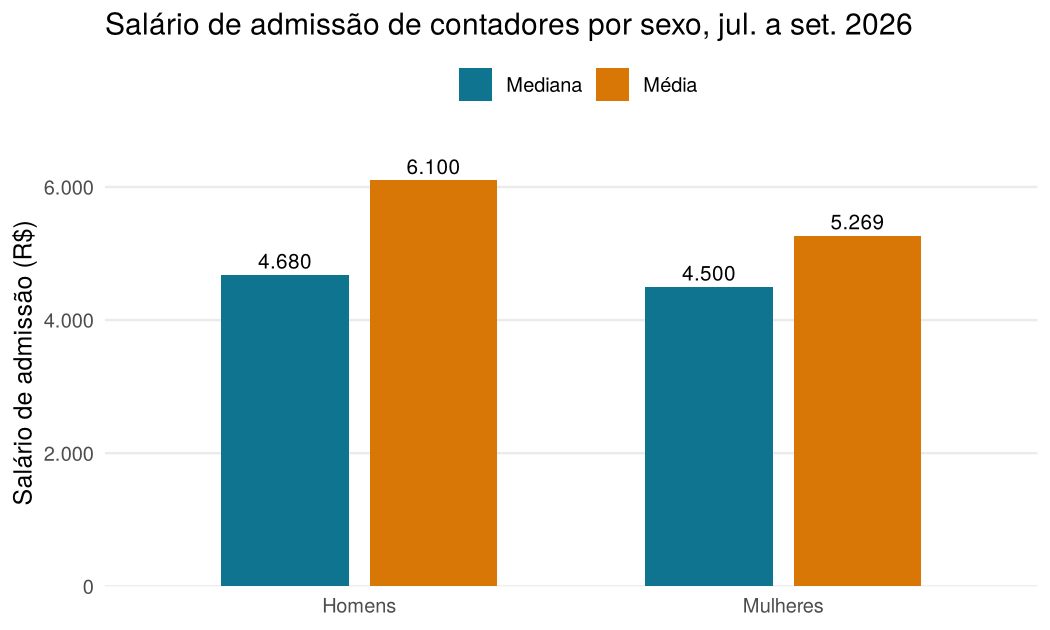

In [8]:
%%R -i contadores -w 7 -h 4.2 --units in -r 150
suppressPackageStartupMessages({library(dplyr); library(ggplot2)})

contadores <- contadores |>
  tidyr::pivot_longer(c(salario_mediano, salario_medio),
                      names_to = "medida", values_to = "salario") |>
  mutate(medida = if_else(medida == "salario_mediano", "Mediana", "Média"))

ggplot(contadores, aes(sexo, salario, fill = medida)) +
  geom_col(position = position_dodge(width = 0.7), width = 0.6) +
  geom_text(aes(label = format(salario, big.mark = ".", decimal.mark = ",")),
            position = position_dodge(width = 0.7), vjust = -0.4, size = 3.5) +
  scale_fill_manual(values = c("Mediana" = "#0e7490", "Média" = "#d97706"), name = NULL) +
  scale_y_continuous(labels = function(x) format(x, big.mark = ".", decimal.mark = ","),
                     expand = expansion(mult = c(0, 0.1))) +
  labs(x = NULL, y = "Salário de admissão (R$)",
       title = "Salário de admissão de contadores por sexo, jul. a set. 2026") +
  theme_minimal(base_size = 12) +
  theme(panel.grid.minor = element_blank(), panel.grid.major.x = element_blank(),
        legend.position = "top")

## Passo 4 (Python): exportar um recorte

O DuckDB permite exportar qualquer consulta para Parquet ou CSV. Retire o comentário para gerar o arquivo com as movimentações do Rio Grande do Norte.

In [9]:
# con.sql("""
#     COPY (SELECT * FROM caged_mov WHERE uf = 24)
#     TO 'caged_rn_2026t3.parquet' (FORMAT parquet)
# """)

con.close()

---

Fonte dos dados: Novo CAGED/Ministério do Trabalho e Emprego (MTE), obtidos com o pacote `datacaged` ([DOI 10.32614/CRAN.package.datacaged](https://doi.org/10.32614/CRAN.package.datacaged)).